# Multivariate Time Series Models I: Vector Autoregressions
**HS 821 · Lecture 11 · Topics in Time Series Econometrics**

**Sunil Paul**

November 2026 · R 4.6

A univariate model can describe each series but cannot say how a disturbance to one is transmitted to another. This lecture introduces the workhorse model for that question, the **vector autoregression** (VAR) of Sims (1980), following Enders (2015, Ch. 5):


## Setup

Most of this lecture is algebra. The R code checks it: it computes the eigenvalues, Cholesky factors, impulse responses and variance decompositions of the worked examples, and runs the application in Section 11. We keep `roots_plot()` from Lectures 6–10 and add three helpers:

- `vma()` — the VMA matrices $\Phi_0,\Phi_1,\dots$ of a VAR with known coefficients (Section 5);
- `fevd_table()` — a variance decomposition from structural impulse responses (Section 8);
- `irf_grid()` — impulse responses in a grid, one panel per variable and shock.

Estimation uses the **vars** package (Pfaff 2008): `VARselect()`, `VAR()`, `roots()`, `serial.test()`, `irf()` and `fevd()`. It also loads **urca**, whose `ur.df()` we used in Lecture 10.

> **R convention.** `chol(S)` returns the **upper**-triangular factor $U$ with $S=U'U$. The lower-triangular $P$ with $S=PP'$ used in this lecture is therefore `t(chol(S))`. The factor depends on the order of the rows and columns of $S$: to put $Z$ first, factor `S[c("Z", "Y"), c("Z", "Y")]` and reorder the result (Section 9). In **vars**, the column order of the data passed to `VAR()` is the ordering used by every orthogonalized result — `Psi()`, `irf(ortho = TRUE)` and `fevd()` — and `irf(ortho = TRUE)` reports responses to **one-standard-deviation** shocks, $\hat\Phi_h\hat P$. `roots()` returns the moduli of the **eigenvalues** of the companion matrix, which must all be below one for stability; they are the reciprocals of the roots of $\det(I-A_1z-\cdots-A_pz^p)$, which must lie outside the unit circle (Section 4).

In [2]:
install.packages("vars")


also installing the dependencies 'MASS', 'strucchange'




package 'MASS' successfully unpacked and MD5 sums checked
package 'strucchange' successfully unpacked and MD5 sums checked
package 'vars' successfully unpacked and MD5 sums checked

The downloaded binary packages are in
	C:\Users\sunilpaul\AppData\Local\Temp\Rtmp4YNwTS\downloaded_packages


In [4]:
# ------------------------------------------------------------------
# Setup: one plotting helper from Lectures 6-10 + three new ones for VARs
# ------------------------------------------------------------------
suppressPackageStartupMessages({
  library(ggplot2)
  library(gridExtra)
  library(vars)        # VAR, VARselect, roots, serial.test, irf, fevd (Pfaff 2008); loads urca
})
options(repr.plot.width = 10, repr.plot.height = 6)

# Roots of a lag polynomial on the complex plane, with the unit circle.
# Roots on the circle (|z| = 1 up to rounding) get their own colour.
roots_plot <- function(roots, title = NULL, tol = 1e-6) {
  theta <- seq(0, 2 * pi, length.out = 400)
  circ  <- data.frame(x = cos(theta), y = sin(theta))
  where <- ifelse(abs(Mod(roots) - 1) < tol, "on the circle",
                  ifelse(Mod(roots) > 1, "outside", "inside"))
  df    <- data.frame(Real = Re(roots), Imaginary = Im(roots), where = where)
  ggplot() + theme_classic() +
    geom_path(data = circ, aes(x, y), colour = "grey55") +
    geom_hline(yintercept = 0) + geom_vline(xintercept = 0) +
    geom_point(data = df, aes(Real, Imaginary, colour = where), size = 3) +
    scale_colour_manual(values = c(outside = "black", inside = "red",
                                   `on the circle` = "blue"), name = NULL) +
    coord_equal() +
    labs(x = "Real part", y = "Imaginary part", title = title)
}

# NEW. VMA (Wold) matrices: Phi_0 = I, Phi_j = sum_{i=1}^{min(j,p)} A_i Phi_{j-i}.
# 'A' is a list of k x k matrices A_1, ..., A_p. Returns a k x k x (h+1) array; [, , j+1] is Phi_j.
vma <- function(A, h = 20) {
  k <- nrow(A[[1]]); p <- length(A)
  Phi <- array(0, c(k, k, h + 1)); Phi[, , 1] <- diag(k)
  for (j in seq_len(h)) for (i in seq_len(min(j, p)))
    Phi[, , j + 1] <- Phi[, , j + 1] + A[[i]] %*% Phi[, , j - i + 1]
  Phi
}

# NEW. Forecast-error variance decomposition from one-s.d. structural responses
# Psi_sd[i, j, h + 1] (variable i, shock j, horizon h). For each n-step horizon: the forecast-error
# variance sum_{h < n} sum_j psi_ij,h^2 and the percentage contributed by each shock.
fevd_table <- function(Psi_sd, horizons, vars = c("Y", "Z"), shocks = c("eps_y", "eps_z")) {
  k    <- dim(Psi_sd)[1]
  grid <- expand.grid(n = horizons, i = seq_len(k))
  res  <- t(mapply(function(n, i) {
    contrib <- rowSums(matrix(Psi_sd[i, , 1:n]^2, nrow = k))
    c(sum(contrib), 100 * contrib / sum(contrib))
  }, grid$n, grid$i))
  out <- data.frame(vars[grid$i], grid$n, round(res[, 1], 4), round(res[, -1, drop = FALSE], 1))
  names(out) <- c("variable", "n-step", "FEV", paste("%", shocks))
  out
}

# NEW. Impulse responses in a k x k grid: rows = responding variable, columns = shock.
# 'irfs' is a named list of k x k x (H+1) arrays, one line each.
irf_grid <- function(irfs, vars = c("Y", "Z"), shocks = c("shock 1", "shock 2"), title = NULL) {
  to_df <- function(a) {
    g <- expand.grid(i = seq_along(vars), j = seq_along(shocks), h = seq_len(dim(a)[3]))
    data.frame(response = factor(paste("Response of", vars[g$i]),
                                 levels = paste("Response of", vars)),
               shock    = factor(shocks[g$j], levels = shocks),
               horizon  = g$h - 1, value = a[cbind(g$i, g$j, g$h)])
  }
  lines <- do.call(rbind, lapply(names(irfs), function(nm) cbind(to_df(irfs[[nm]]), series = nm)))
  lines$series <- factor(lines$series, levels = names(irfs))
  m <- length(irfs)
  ggplot(lines, aes(horizon, value, colour = series, linetype = series)) + theme_classic() +
    geom_hline(yintercept = 0, colour = "grey60") + geom_line() +
    facet_grid(response ~ shock) +
    scale_colour_manual(values = c("black", "red", "blue", "darkgreen")[1:m], name = NULL) +
    scale_linetype_manual(values = c("solid", "dashed", "dotted", "dotdash")[1:m], name = NULL) +
    scale_x_continuous(breaks = seq(0, dim(irfs[[1]])[3] - 1, by = 4)) +
    labs(x = "Horizon", y = "Response", title = title) +
    theme(legend.position = "bottom", legend.key.width = unit(1.2, "cm"),
          legend.text = element_text(margin = margin(r = 12)))
}

# 1&nbsp;&nbsp;Why model several series together

## Uses of time-series econometric analysis

Time-series econometrics serves four broad purposes.

1. **Data description.** Summarize the salient features of observed series — levels, growth rates, seasonality, volatility clustering and co-movements — so that modelling choices are grounded in how the data behave.
2. **Forecasting.** Build models that predict future values, and evaluate them by comparing the forecasts with the outcomes.
3. **Structural inference.** Go beyond correlations to quantify what we do and do not know about the underlying economic structure: how shocks propagate, and through which channels.
4. **Policy analysis.** With a defensible structural interpretation in hand, trace out counterfactuals — how output, inflation or asset prices would respond to a monetary, fiscal or technology shock — recognizing that the conclusions are only as good as the structural assumptions behind them.

The first two can be done with **reduced-form** models. The last two need a **structural** interpretation, and the gap between the two is the main theme of this lecture.

## Single-equation versus multi-equation models

A **single-equation model** explains one variable at a time. The univariate AR($p$) of Lectures 6–9 explains $Y_t$ by its own lags. It is parsimonious, useful for short-run forecasting, and isolates the univariate dynamics of a series. A distributed-lag or transfer-function model adds other variables as regressors, but treats them as **exogenous**: $Z$ may affect $Y$, but $Y$ is assumed not to feed back on $Z$.

A **multi-equation model** studies the joint evolution of several variables and allows feedback in every direction. In a $k$-variable **VAR of order $p$**, VAR($p$), each variable is regressed on $p$ lags of **itself and of every other variable** in the system. The VAR extends the univariate AR to systems and treats all variables symmetrically: none has to be declared exogenous in advance. That was Sims's (1980) point. The large structural macroeconometric models of the 1960s and 1970s achieved identification through exclusion restrictions he called "incredible"; a VAR lets the data describe the dynamics before any structure is imposed.

The price, as Section 7 shows, is that structure must still be imposed **somewhere** before the results can be given an economic interpretation.

| | Univariate AR($p$) | Transfer function / distributed lag | VAR($p$) |
|---|---|---|---|
| Variables explained | one | one | all $k$ |
| Other variables | none | exogenous regressors | endogenous, with feedback |
| Equations | 1 | 1 | $k$ |
| Coefficients on lags | $p$ | $p$ + lags of the regressors | $k^2p$ |
| Typical use | univariate forecasting | effect of a known input | dynamic interactions, shock transmission |

# 2&nbsp;&nbsp;From the structural VAR to the reduced form

## A bivariate structural VAR

Let $Y_t$ and $Z_t$ be two stationary series. The simplest system in which each can affect the other, both within the period and with a lag, is the first-order **structural VAR** — Enders's **primitive system**:

$$
\begin{aligned}
Y_t &= b_{10} - b_{12}Z_t + c_{11}Y_{t-1} + c_{12}Z_{t-1} + \varepsilon_{yt},\\
Z_t &= b_{20} - b_{21}Y_t + c_{21}Y_{t-1} + c_{22}Z_{t-1} + \varepsilon_{zt},
\end{aligned}
$$

where $Y_t\sim I(0)$ and $Z_t\sim I(0)$; $\varepsilon_{yt}\sim\text{WN}(0,\sigma_y^2)$ and $\varepsilon_{zt}\sim\text{WN}(0,\sigma_z^2)$ are the **structural shocks**; and the two shocks are uncorrelated, $E(\varepsilon_{yt}\varepsilon_{zt})=0$. In VAR terminology the **order** is $p=1$, the longest lag, and the **dimension** is $k=2$, the number of variables.

The system has **feedback**. $-b_{12}$ is the contemporaneous effect of $Z_t$ on $Y_t$, and $-b_{21}$ the contemporaneous effect of $Y_t$ on $Z_t$. If $b_{12}\neq0$, the shock $\varepsilon_{zt}$ has an indirect contemporaneous effect on $Y_t$ through $Z_t$; if $b_{21}\neq0$, $\varepsilon_{yt}$ has an indirect contemporaneous effect on $Z_t$ through $Y_t$. Each structural shock is a "pure" disturbance with an economic label — a demand shock, a policy shock — and the coefficients $b_{ij}$ and $c_{ij}$ describe behaviour.

**The structural equations cannot be estimated by OLS.** Because $Z_t$ responds to $\varepsilon_{yt}$ (through $b_{21}$), the regressor $Z_t$ in the first equation is correlated with that equation's error. Using the reduced form derived below,

$$
\operatorname{Cov}(Z_t,\varepsilon_{yt})=\frac{-b_{21}\,\sigma_y^2}{1-b_{12}b_{21}}\neq0\qquad\text{whenever }b_{21}\neq0 ,
$$

and likewise $\operatorname{Cov}(Y_t,\varepsilon_{zt})\neq0$ whenever $b_{12}\neq0$. This is the simultaneous-equations problem: OLS estimates of the structural coefficients are inconsistent.

## Matrix form

Moving the contemporaneous terms to the left gives the compact **structural** form

$$
\underbrace{\begin{bmatrix}1&b_{12}\\b_{21}&1\end{bmatrix}}_{B}
\underbrace{\begin{bmatrix}Y_t\\Z_t\end{bmatrix}}_{X_t}
=
\underbrace{\begin{bmatrix}b_{10}\\b_{20}\end{bmatrix}}_{\Gamma_0}
+
\underbrace{\begin{bmatrix}c_{11}&c_{12}\\c_{21}&c_{22}\end{bmatrix}}_{\Gamma_1}
\underbrace{\begin{bmatrix}Y_{t-1}\\Z_{t-1}\end{bmatrix}}_{X_{t-1}}
+
\underbrace{\begin{bmatrix}\varepsilon_{yt}\\\varepsilon_{zt}\end{bmatrix}}_{\varepsilon_t},
\qquad\text{i.e.}\qquad
BX_t=\Gamma_0+\Gamma_1X_{t-1}+\varepsilon_t .
$$

This is the **structural VAR (SVAR)**. The label "structural" reflects that the contemporaneous matrix $B$ encodes behavioural or technological relationships that we hope to interpret economically.

> **Sign convention.** Following Enders, the contemporaneous coefficients enter the equations with a minus sign, $Y_t=b_{10}-b_{12}Z_t+\cdots$, so that they appear with a plus sign in $B$. Every formula in this lecture uses this convention. Some texts and software write $Y_t=b_{12}Z_t+\cdots$ instead, which flips the sign of the off-diagonal elements of $B$; the economics is unchanged as long as one convention is used throughout.

## The reduced form

If $B$ is nonsingular ($1-b_{12}b_{21}\neq0$), premultiplying by $B^{-1}$ gives the **reduced form** (Enders's **standard form**):

$$
X_t=A_0+A_1X_{t-1}+e_t,\qquad A_0=B^{-1}\Gamma_0,\quad A_1=B^{-1}\Gamma_1,\quad e_t=B^{-1}\varepsilon_t ,
$$

or, in components,

$$
\begin{bmatrix}Y_t\\Z_t\end{bmatrix}
=
\begin{bmatrix}a_{10}\\a_{20}\end{bmatrix}
+
\begin{bmatrix}a_{11}&a_{12}\\a_{21}&a_{22}\end{bmatrix}
\begin{bmatrix}Y_{t-1}\\Z_{t-1}\end{bmatrix}
+
\begin{bmatrix}e_{1t}\\e_{2t}\end{bmatrix}.
$$

With $p$ lags the same steps turn $BX_t=\Gamma_0+\Gamma_1X_{t-1}+\cdots+\Gamma_pX_{t-p}+\varepsilon_t$ into $X_t=A_0+A_1X_{t-1}+\cdots+A_pX_{t-p}+e_t$ with $A_i=B^{-1}\Gamma_i$.

- **OLS works.** The right-hand side contains only lagged (predetermined) variables, uncorrelated with $e_t$, so OLS equation by equation is consistent. Because every equation has the same regressors, it is also efficient: seemingly unrelated regressions (Zellner 1962) collapse to OLS.
- **The contemporaneous structure has been absorbed.** The reduced form is an **unrestricted** VAR: $A_0$, $A_1$ and $e_t$ mix the structural parameters. For example $a_{21}=(c_{21}-b_{21}c_{11})/(1-b_{12}b_{21})$, so lagged $Y$ can predict $Z$ even when $c_{21}=0$, because $Y_{t-1}$ moves $Y_t$, which moves $Z_t$ within the period.
- **The errors are mixtures.** Each $e_{it}$ combines both structural shocks, and $e_{1t}$ and $e_{2t}$ are correlated (Section 3).

# 3&nbsp;&nbsp;Structural shocks and reduced-form errors

## The errors are mixtures

By construction $e_t=B^{-1}\varepsilon_t$. In the bivariate case

$$
B^{-1}=\frac{1}{\det B}\operatorname{adj}(B)=\frac{1}{1-b_{12}b_{21}}\begin{bmatrix}1&-b_{12}\\-b_{21}&1\end{bmatrix},
$$

so that

$$
e_{1t}=\frac{\varepsilon_{yt}-b_{12}\varepsilon_{zt}}{1-b_{12}b_{21}},
\qquad
e_{2t}=\frac{\varepsilon_{zt}-b_{21}\varepsilon_{yt}}{1-b_{12}b_{21}} .
$$

Each reduced-form error is a weighted sum of **both** structural shocks. Because $\varepsilon_{yt}$ and $\varepsilon_{zt}$ are white noise, so is each $e_{it}$:

$$
E(e_{it})=0,\qquad \operatorname{Var}(e_{it})\ \text{constant},\qquad E(e_{it}e_{i,t-j})=0\quad\text{for } j\neq0 .
$$

## Variances and the covariance

$$
\operatorname{Var}(e_{1t})=\frac{\sigma_y^2+b_{12}^2\sigma_z^2}{(1-b_{12}b_{21})^2},
\qquad
\operatorname{Var}(e_{2t})=\frac{b_{21}^2\sigma_y^2+\sigma_z^2}{(1-b_{12}b_{21})^2},
\qquad
\operatorname{Cov}(e_{1t},e_{2t})=-\frac{b_{21}\sigma_y^2+b_{12}\sigma_z^2}{(1-b_{12}b_{21})^2}.
$$

None of these depends on $t$, so the reduced-form covariance matrix is constant:

$$
\Sigma_e=E(e_te_t')=\begin{bmatrix}\sigma_1^2&\sigma_{12}\\\sigma_{12}&\sigma_2^2\end{bmatrix}
=B^{-1}\Sigma_\varepsilon B^{-1\prime},
\qquad
\Sigma_\varepsilon=E(\varepsilon_t\varepsilon_t')=\begin{bmatrix}\sigma_y^2&0\\0&\sigma_z^2\end{bmatrix}.
$$

The covariance is zero if there are no contemporaneous effects, $b_{12}=b_{21}=0$, and otherwise only in the knife-edge case $b_{21}\sigma_y^2=-b_{12}\sigma_z^2$. In general, then, the reduced-form errors are serially uncorrelated but **correlated across equations**.

This correlation is the root of the **identification problem** of Section 7. The data deliver $\Sigma_e$, which has three distinct elements, but $\Sigma_e$ depends on four unknowns: $b_{12}$, $b_{21}$, $\sigma_y^2$ and $\sigma_z^2$.

# 4&nbsp;&nbsp;Stability and stationarity

## The first-order VAR

Write the reduced form in deviations from its mean, $X_t=A_1X_{t-1}+e_t$, or $(I-A_1L)X_t=e_t$, with

$$
X_t=\begin{bmatrix}Y_t\\Z_t\end{bmatrix},\qquad A_1=\begin{bmatrix}a_{11}&a_{12}\\a_{21}&a_{22}\end{bmatrix}.
$$

Iterating backwards from a starting value $X_0$,

$$
X_t=A_1^{\,t}X_0+\sum_{j=0}^{t-1}A_1^{\,j}e_{t-j}.
$$

The VAR is **stable** if the effect of the starting value, and of any single shock, dies out: $A_1^{\,j}\to0$ as $j\to\infty$. This holds if and only if every eigenvalue $\lambda$ of $A_1$ has modulus strictly less than one. A stable VAR is covariance stationary once its starting values have been forgotten, which is why the stability condition is also called the stationarity condition (Lütkepohl 2005, Section 2.1).

Equivalently, in terms of the lag polynomial, the roots of

$$
\det(I-A_1z)=(1-a_{11}z)(1-a_{22}z)-a_{12}a_{21}z^2=(1-\lambda_1z)(1-\lambda_2z)
$$

must lie **outside** the unit circle. The roots are $z_i=1/\lambda_i$: the eigenvalues of $A_1$ are the **inverse roots**, exactly as in the AR(2) factorization of Lecture 10. If $a_{12}=a_{21}=0$ (a diagonal VAR), the system is two unrelated AR(1)s and the condition reduces to $|a_{11}|<1$ and $|a_{22}|<1$.

Both variables inherit this second-order polynomial. Multiplying $(I-A_1L)X_t=e_t$ by the adjugate of $I-A_1L$ gives, for the first variable,

$$
\det(I-A_1L)\,Y_t=(1-a_{22}L)\,e_{1t}+a_{12}\,e_{2,t-1},
$$

and the right-hand side, a sum of MA(1) terms, is an MA(1). So $Y_t$ is a univariate ARMA(2,1), and so is $Z_t$, with the **same** AR polynomial (Enders 2015, Ch. 5). A first-order VAR can therefore produce the humps and oscillations of an AR(2), and a series that looks like a univariate ARMA may be one element of a small VAR.

## The VAR($p$) and the companion form

For the VAR($p$)

$$
X_t=A_0+A_1X_{t-1}+\cdots+A_pX_{t-p}+e_t ,
$$

stack $p$ consecutive vectors into the $kp$-vector $\mathbf X_t$ to obtain a VAR(1), the **companion form**:

$$
\underbrace{\begin{bmatrix}X_t\\X_{t-1}\\\vdots\\X_{t-p+1}\end{bmatrix}}_{\mathbf X_t}
=
\underbrace{\begin{bmatrix}A_0\\0\\\vdots\\0\end{bmatrix}}_{\Pi_0}
+
\underbrace{\begin{bmatrix}
A_1&A_2&\cdots&A_{p-1}&A_p\\
I&0&\cdots&0&0\\
0&I&\cdots&0&0\\
\vdots&\vdots&\ddots&\vdots&\vdots\\
0&0&\cdots&I&0
\end{bmatrix}}_{\Pi_1}
\underbrace{\begin{bmatrix}X_{t-1}\\X_{t-2}\\\vdots\\X_{t-p}\end{bmatrix}}_{\mathbf X_{t-1}}
+
\underbrace{\begin{bmatrix}e_t\\0\\\vdots\\0\end{bmatrix}}_{E_t}.
$$

The VAR($p$) is **stable** if and only if **all $kp$ eigenvalues** of $\Pi_1$ have modulus strictly less than one; equivalently, all roots of the degree-$kp$ polynomial

$$
\det(I-A_1z-A_2z^2-\cdots-A_pz^p)=0
$$

lie outside the unit circle. Stability is a property of the whole system: it cannot be read from the size of the individual coefficients.

**A unit root in a VAR.** If $z=1$ is a root, then $\det(I-A_1-\cdots-A_p)=\det A(1)=0$ — the multivariate version of $\phi(1)=0$ in Lecture 10. At least one linear combination of the variables then contains a stochastic trend. Whether some **other** combination is stationary is the question of cointegration.

## Illustrations

**A persistent system.** Let

$$
A_1=\begin{bmatrix}0.625&0.5\\0.25&0.625\end{bmatrix}.
$$

The characteristic equation is $\det(A_1-\lambda I)=(0.625-\lambda)^2-0.125=0$, so $\lambda=0.625\pm\sqrt{0.125}$: $\lambda_1\approx0.979$ and $\lambda_2\approx0.271$. Both are below one in modulus, so the VAR is stable and hence stationary. In lag-polynomial form,

$$
\det(I-A_1z)=(1-0.625z)^2-0.125z^2=(1-0.979z)(1-0.271z),
$$

with roots $z_1\approx1.022$ and $z_2\approx3.684$, both outside the unit circle. Stable — but only just.

**The system of Section 9.** For

$$
A_1=\begin{bmatrix}0.7&0.2\\0.2&0.7\end{bmatrix},
\qquad
\det(I-A_1z)=(1-0.7z)^2-(0.2z)^2=1-1.4z+0.45z^2 ,
$$

the roots are $z_1=2$ and $z_2=1/0.9\approx1.111$, both outside the unit circle, and the eigenvalues of $A_1$ are their inverses, $0.5$ and $0.9$. The VAR is stable, which guarantees that its impulse responses converge to zero and that long-run cumulated effects are finite.

### Predict

The largest eigenvalue governs how fast a shock dies out: the slowest component of the response shrinks by the factor $\lambda_{\max}$ each period. How many periods does it take that component to halve in each system? Which system's impulse responses will still be visibly different from zero after 20 periods?

Example1             eigenvalues: 0.979, 0.271    roots z: 1.022, 3.684    1/roots: 0.979, 0.271    half-life: 32.0 periods
Example2             eigenvalues: 0.900, 0.500    roots z: 1.111, 2.000    1/roots: 0.900, 0.500    half-life: 6.6 periods


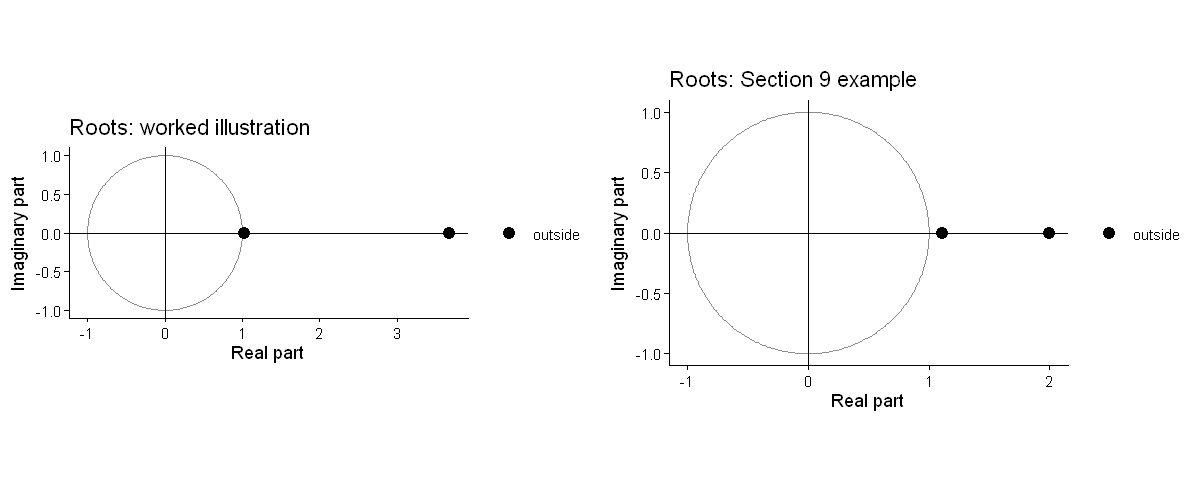

In [5]:
# Stability of the two first-order examples: eigenvalues of A1 and roots of det(I - A1 z)
examples <- list(
  `Example1` = matrix(c(0.625, 0.5,  0.25, 0.625), 2, 2, byrow = TRUE),
  `Example2`   = matrix(c(0.7,   0.2,  0.2,  0.7  ), 2, 2, byrow = TRUE))
z_roots <- list()
for (nm in names(examples)) {
  A  <- examples[[nm]]
  ev <- eigen(A)$values
  z  <- polyroot(c(1, -sum(diag(A)), det(A)))     # 2 x 2: det(I - A z) = 1 - tr(A) z + det(A) z^2
  z_roots[[nm]] <- z
  cat(sprintf("%-20s eigenvalues: %s    roots z: %s    1/roots: %s    half-life: %.1f periods\n",
              nm, paste(sprintf("%.3f", ev), collapse = ", "),
              paste(sprintf("%.3f", sort(Re(z))), collapse = ", "),
              paste(sprintf("%.3f", sort(1 / Re(z), decreasing = TRUE)), collapse = ", "),
              log(0.5) / log(max(Mod(ev)))))
}
options(repr.plot.height = 4)
grid.arrange(roots_plot(z_roots[[1]], title = "Roots: worked illustration"),
             roots_plot(z_roots[[2]], title = "Roots: Section 9 example"), ncol = 2)
options(repr.plot.height = 6)

**Reading the output.** The eigenvalues and roots confirm the algebra: $0.979$ and $0.271$ (roots $1.022$ and $3.684$) for the persistent system, and $0.9$ and $0.5$ (roots $1.111$ and $2$) for the Section 9 system. In both cases the reciprocals of the roots are the eigenvalues, and both pairs of roots lie outside the unit circle (black). The half-life of the slowest component is $\ln0.5/\ln\lambda_{\max}$: 32 periods for the persistent system, whose root sits just outside the circle, against 6.6 periods for the Section 9 system. After 20 periods a shock to the persistent system has lost only about a third of its slow component ($0.979^{20}\approx0.65$), while one to the Section 9 system has lost about 90% ($0.9^{20}\approx0.12$).

# 5&nbsp;&nbsp;The vector moving-average (Wold) representation

## From the VAR to the VMA

Let $A(L)=I-A_1L-\cdots-A_pL^p$ be the lag polynomial of the reduced form, so that $A(L)X_t=A_0+e_t$. If the VAR is stable, $A(L)^{-1}$ exists as a convergent power series, and

$$
X_t=\mu+\sum_{j=0}^{\infty}\Phi_je_{t-j},
\qquad
\mu=A(1)^{-1}A_0=(I-A_1-\cdots-A_p)^{-1}A_0,
\qquad
\Phi_0=I,
\qquad
\Phi_j\to0\ \ (j\to\infty).
$$

This is the **vector moving-average (VMA)** or multivariate **Wold representation** (Wold 1938; Lectures 6–8 for the univariate case): every stationary VAR is a VMA($\infty$) in its own one-step-ahead forecast errors $e_t$.

**First order.** For $X_t=A_0+A_1X_{t-1}+e_t$,

$$
(I-A_1L)^{-1}=I+A_1L+A_1^2L^2+\cdots=\sum_{j=0}^{\infty}A_1^{\,j}L^j ,
$$

so

$$
X_t=(I-A_1)^{-1}A_0+\sum_{j=0}^{\infty}A_1^{\,j}e_{t-j}
=\overline X+\sum_{j=0}^{\infty}A_1^{\,j}e_{t-j},
\qquad \Phi_j=A_1^{\,j},
$$

with $\overline X=(I-A_1)^{-1}A_0$, which exists whenever $I-A_1$ is nonsingular. In components,

$$
\begin{bmatrix}Y_t\\Z_t\end{bmatrix}
=
\begin{bmatrix}\overline Y\\\overline Z\end{bmatrix}
+
\sum_{j=0}^{\infty}
\begin{bmatrix}a_{11}&a_{12}\\a_{21}&a_{22}\end{bmatrix}^{j}
\begin{bmatrix}e_{1,t-j}\\e_{2,t-j}\end{bmatrix}.
$$

**Order $p$.** Matching powers of $L$ in $A(L)\Phi(L)=I$ gives the recursion that `vma()` implements:

$$
\Phi_0=I,\qquad \Phi_j=\sum_{i=1}^{\min(j,p)}A_i\Phi_{j-i}\quad(j\ge1).
$$

## What the VMA delivers

- **The mean:** $E(X_t)=\mu$.
- **The variance:** $\operatorname{Var}(X_t)=\sum_{j=0}^{\infty}\Phi_j\Sigma_e\Phi_j'$. For a VAR(1) it also solves $\operatorname{Var}(X_t)=A_1\operatorname{Var}(X_t)A_1'+\Sigma_e$.
- **Forecast errors:** the $n$-step-ahead forecast error is $X_{t+n}-E_tX_{t+n}=\sum_{j=0}^{n-1}\Phi_je_{t+n-j}$. The $\Phi_j$ are the weights with which today's forecast errors move future values: they are the forecast-error impulse responses of Section 6, and they are the building blocks of the variance decomposition of Section 8.

# 6&nbsp;&nbsp;Impulse response functions

## Forecast-error impulse responses

The VMA representation is the basis of **impulse response analysis**. Write

$$
X_t=\mu+\Phi_0e_t+\Phi_1e_{t-1}+\Phi_2e_{t-2}+\cdots,
$$

with $\Phi_0=I$ and, for a VAR(1), $\Phi_j=A_1^{\,j}$. The elements of $\Phi_h$ are the **forecast-error impulse responses**:

$$
\phi_{ij,h}=\frac{\partial X_{i,t+h}}{\partial e_{jt}},
$$

the response of variable $i$, $h$ periods later, to a one-unit **reduced-form** innovation in equation $j$ at time $t$. In the bivariate case, for example, $\phi_{11,1}=\partial Y_{t+1}/\partial e_{1t}$ and $\phi_{12,1}=\partial Y_{t+1}/\partial e_{2t}$. Plotting $\phi_{ij,h}$ against $h$ gives the impulse response function.

These responses have two problems.

1. **$\Phi_0=I$.** A unit $e_{1t}$ moves only $Y_t$ on impact, with $e_{2t}$ held at zero. But $e_{1t}$ and $e_{2t}$ are correlated (Section 3), so in the data an innovation in one equation typically comes with an innovation in the other. The experiment "$e_1$ moves, $e_2$ does not" is not representative.
2. **No economic label.** Each $e_{jt}$ is a mixture of the structural shocks, so a response to $e_{1t}$ is not the response to any economically meaningful disturbance.

## Structural impulse responses

To obtain **economically interpretable** responses, express the VMA in the structural shocks. Substituting $e_t=B^{-1}\varepsilon_t$,

$$
X_t=\mu+\sum_{j=0}^{\infty}\Phi_je_{t-j}
=\mu+\sum_{j=0}^{\infty}\Phi_jB^{-1}\varepsilon_{t-j}
=\mu+\sum_{j=0}^{\infty}\Psi_j\varepsilon_{t-j},
\qquad
\Psi_j=\Phi_jB^{-1}.
$$

The elements of $\Psi_h$ are the **structural impulse responses**:

$$
\psi_{ij,h}=\frac{\partial X_{i,t+h}}{\partial\varepsilon_{jt}},
$$

the dynamic effect on variable $i$ of a one-unit structural shock of type $j$, $h$ periods after it hits; for example $\psi_{12,1}=\partial Y_{t+1}/\partial\varepsilon_{zt}$. The **impact matrix** $\Psi_0=B^{-1}$ is the contemporaneous structure itself, and for a VAR(1) the responses follow the recursion $\Psi_h=A_1\Psi_{h-1}$.

- **Decay.** For a stable VAR, $\Psi_h\to0$ as $h\to\infty$.
- **Cumulated responses.** The cumulated effect up to horizon $H$ is $\sum_{h=0}^{H}\Psi_h$, and the **long-run** cumulated effect is $\sum_{h=0}^{\infty}\Psi_h=A(1)^{-1}B^{-1}$; for a VAR(1), $(I-A_1)^{-1}B^{-1}$. If $X_t$ contains growth rates, the cumulated response of a growth rate is the response of the **level** — the multivariate counterpart of the long-run impact $\psi^\ast(1)$ in Lecture 10.
- **Scaling.** IRFs are often reported for a **one-standard-deviation** structural shock, $\Psi_h\Sigma_\varepsilon^{1/2}$. Scaling changes magnitudes, not shapes.
- **The ordering shapes the impact.** Under a recursive scheme (Section 7) in which $Z$ does not respond to $Y$ within the period, $B^{-1}$ is triangular: an $\varepsilon_{y}$ shock leaves $Z_t$ unchanged on impact and reaches $Z_{t+h}$, $h\ge1$, only through the lag dynamics, while an $\varepsilon_{z}$ shock moves both $Z_t$ and $Y_t$ at once. Change the ordering and the impact pattern changes with it.

# 7&nbsp;&nbsp;Identification: from the reduced form back to the structure

## Why the reduced form is not enough

The reduced form can be estimated consistently by OLS because its right-hand side contains only predetermined variables and its errors are white noise — serially uncorrelated, though correlated across equations. The structural form cannot, because its contemporaneous terms are correlated with the structural shocks (Section 2). Our goal is to **recover the primitive system** — the contemporaneous relations in $B$ and the orthogonal shocks $\varepsilon_t$ — from the reduced-form estimates. **Identification** is precisely this inversion problem: from $\hat A_0,\hat A_1,\dots,\hat A_p$ and $\hat\Sigma_e$, can we uniquely recover the structural parameters and shocks? Sims (1980) emphasized that without **restrictions** on the primitive system the answer is no.

## Counting parameters

In the bivariate VAR(1) (Enders 2015, Ch. 5):

| | Reduced form | Structural form |
|---|---|---|
| Intercepts | $a_{10},a_{20}$: 2 | $b_{10},b_{20}$: 2 |
| Lag coefficients | $a_{11},a_{12},a_{21},a_{22}$: 4 | $c_{11},c_{12},c_{21},c_{22}$: 4 |
| Contemporaneous coefficients | — | $b_{12},b_{21}$: 2 |
| Shock (co)variances | $\sigma_1^2,\sigma_2^2,\sigma_{12}$: 3 | $\sigma_y^2,\sigma_z^2$: 2 |
| **Total** | **9** | **10** |

The structural model is **under-identified by one parameter**: at least one restriction is needed. Given $B$, everything else follows at once ($\Gamma_i=BA_i$), so the whole problem lies in the link between $\Sigma_e$ and $(B,\Sigma_\varepsilon)$:

$$
\Sigma_e=B^{-1}\Sigma_\varepsilon B^{-1\prime}
\quad\Longleftrightarrow\quad
\Sigma_\varepsilon=B\,\Sigma_e\,B' ,
$$

that is,

$$
\begin{bmatrix}\sigma_1^2&\sigma_{12}\\\sigma_{12}&\sigma_2^2\end{bmatrix}
=
\frac{1}{\Delta}\begin{bmatrix}1&-b_{12}\\-b_{21}&1\end{bmatrix}
\begin{bmatrix}\sigma_y^2&0\\0&\sigma_z^2\end{bmatrix}
\frac{1}{\Delta}\begin{bmatrix}1&-b_{21}\\-b_{12}&1\end{bmatrix},
\qquad \Delta=1-b_{12}b_{21}:
$$

three distinct elements on the left, four unknowns on the right.

**In general.** With $k$ variables, $\Sigma_e$ is symmetric and has $k(k+1)/2$ distinct elements. The unknowns are the $k(k-1)$ off-diagonal elements of $B$ (its diagonal is normalized to one) and the $k$ variances in $\Sigma_\varepsilon=\operatorname{diag}(\sigma_{\varepsilon1}^2,\dots,\sigma_{\varepsilon k}^2)$: $k^2$ in all. We are short of

$$
k^2-\frac{k(k+1)}{2}=\frac{k(k-1)}{2}
$$

restrictions — the number of elements in one triangle of $B$: 1 when $k=2$, 3 when $k=3$, 10 when $k=5$.

## Recursive identification

The most common restriction is a **recursive ordering** (Sims 1980): variables earlier in the ordering may affect later ones within the period, but not vice versa. In the bivariate model, suppose $Y_t$ may respond contemporaneously to $Z_t$ but $Z_t$ does **not** respond contemporaneously to $Y_t$: $b_{21}=0$, and $Z$ is ordered first. The primitive system becomes

$$
\begin{aligned}
Y_t &= b_{10}-b_{12}Z_t+c_{11}Y_{t-1}+c_{12}Z_{t-1}+\varepsilon_{yt},\\
Z_t &= b_{20}\phantom{{}-b_{12}Z_t}+c_{21}Y_{t-1}+c_{22}Z_{t-1}+\varepsilon_{zt},
\end{aligned}
\qquad
B=\begin{bmatrix}1&b_{12}\\0&1\end{bmatrix},
\qquad
B^{-1}=\begin{bmatrix}1&-b_{12}\\0&1\end{bmatrix}.
$$

Premultiplying by $B^{-1}$ and matching coefficients with the reduced form gives

$$
\begin{aligned}
a_{10}&=b_{10}-b_{12}b_{20}, & a_{20}&=b_{20},\\
a_{11}&=c_{11}-b_{12}c_{21}, & a_{21}&=c_{21},\\
a_{12}&=c_{12}-b_{12}c_{22}, & a_{22}&=c_{22},\\
e_{1t}&=\varepsilon_{yt}-b_{12}\varepsilon_{zt}, & e_{2t}&=\varepsilon_{zt},
\end{aligned}
$$

and the reduced-form covariance matrix becomes

$$
\operatorname{Var}(e_{1t})=\sigma_y^2+b_{12}^2\sigma_z^2,\qquad
\operatorname{Var}(e_{2t})=\sigma_z^2,\qquad
\operatorname{Cov}(e_{1t},e_{2t})=-b_{12}\sigma_z^2 .
$$

Three equations in three unknowns, with the unique solution

$$
\sigma_z^2=\sigma_2^2,\qquad
b_{12}=-\frac{\sigma_{12}}{\sigma_2^2},\qquad
\sigma_y^2=\sigma_1^2-\frac{\sigma_{12}^2}{\sigma_2^2}.
$$

The model is now **exactly identified**: the structural parameters follow from the reduced form — $b_{20}=a_{20}$, $c_{21}=a_{21}$, $c_{22}=a_{22}$, $b_{10}=a_{10}+b_{12}a_{20}$, $c_{11}=a_{11}+b_{12}a_{21}$, $c_{12}=a_{12}+b_{12}a_{22}$ — and so do the structural shocks, $\varepsilon_{zt}=e_{2t}$ and $\varepsilon_{yt}=e_{1t}+b_{12}e_{2t}$. With $k$ variables, a recursive ordering sets one whole triangle of $B$ to zero, reducing its free elements from $k(k-1)$ to $k(k-1)/2$: exactly the $k(k-1)/2$ restrictions required.

## The Cholesky factorization does it in one step

Write the structural covariance matrix as a square root times itself, $\Sigma_\varepsilon=\Sigma_\varepsilon^{1/2}\Sigma_\varepsilon^{1/2}$ with $\Sigma_\varepsilon^{1/2}=\operatorname{diag}(\sigma_y,\sigma_z)$. Then

$$
\Sigma_e=B^{-1}\Sigma_\varepsilon B^{-1\prime}
=\big(B^{-1}\Sigma_\varepsilon^{1/2}\big)\big(B^{-1}\Sigma_\varepsilon^{1/2}\big)'
=PP',
\qquad P\equiv B^{-1}\Sigma_\varepsilon^{1/2}.
$$

Under a recursive ordering $B^{-1}$ is triangular with ones on the diagonal, so $P$ is triangular with the structural standard deviations on its diagonal. A symmetric positive definite matrix has exactly one factorization $PP'$ with $P$ lower triangular and a positive diagonal — its **Cholesky factorization**. So, once the variables are listed in the chosen order, **computing the Cholesky factor of $\Sigma_e$ is the same as solving for $B$ and $\Sigma_\varepsilon$**:

- the diagonal of $P$ holds the structural standard deviations;
- dividing each column of $P$ by its diagonal element gives $B^{-1}$;
- the columns of $P$ are the impact responses to **one-standard-deviation** structural shocks, and the **orthogonalized** impulse responses are $\Phi_hP=\Psi_h\Sigma_\varepsilon^{1/2}$.

For a general symmetric positive definite $k\times k$ matrix,

$$
\begin{bmatrix}
a_{11}&a_{12}&\cdots&a_{1k}\\
a_{12}&a_{22}&\cdots&a_{2k}\\
\vdots&\vdots&\ddots&\vdots\\
a_{1k}&a_{2k}&\cdots&a_{kk}
\end{bmatrix}
=
\underbrace{\begin{bmatrix}
u_{11}&0&\cdots&0\\
u_{12}&u_{22}&\cdots&0\\
\vdots&\vdots&\ddots&\vdots\\
u_{1k}&u_{2k}&\cdots&u_{kk}
\end{bmatrix}}_{P=U'}
\underbrace{\begin{bmatrix}
u_{11}&u_{12}&\cdots&u_{1k}\\
0&u_{22}&\cdots&u_{2k}\\
\vdots&\vdots&\ddots&\vdots\\
0&0&\cdots&u_{kk}
\end{bmatrix}}_{U},
$$

and in the $2\times2$ case the factor can be written down directly:

$$
\begin{bmatrix}a_{11}&a_{12}\\a_{12}&a_{22}\end{bmatrix}
=
\begin{bmatrix}\sqrt{a_{11}}&0\\[2pt]\dfrac{a_{12}}{\sqrt{a_{11}}}&\sqrt{a_{22}-\dfrac{a_{12}^2}{a_{11}}}\end{bmatrix}
\begin{bmatrix}\sqrt{a_{11}}&\dfrac{a_{12}}{\sqrt{a_{11}}}\\[2pt]0&\sqrt{a_{22}-\dfrac{a_{12}^2}{a_{11}}}\end{bmatrix}.
$$

**Example: $Y$ ordered first.** Setting $b_{12}=0$ instead gives

$$
B=\begin{bmatrix}1&0\\b_{21}&1\end{bmatrix},\qquad
B^{-1}=\begin{bmatrix}1&0\\-b_{21}&1\end{bmatrix},\qquad
P=B^{-1}\Sigma_\varepsilon^{1/2}=\begin{bmatrix}\sigma_y&0\\-b_{21}\sigma_y&\sigma_z\end{bmatrix},
$$

so that

$$
PP'=\begin{bmatrix}\sigma_y^2&-b_{21}\sigma_y^2\\-b_{21}\sigma_y^2&b_{21}^2\sigma_y^2+\sigma_z^2\end{bmatrix}=\Sigma_e .
$$

Equating elements — or applying the $2\times2$ formula with $a_{11}=\sigma_1^2$, $a_{12}=\sigma_{12}$, $a_{22}=\sigma_2^2$ — gives

$$
\sigma_y^2=\sigma_1^2,\qquad
b_{21}=-\frac{\sigma_{12}}{\sigma_1^2},\qquad
\sigma_z^2=\sigma_2^2-\frac{\sigma_{12}^2}{\sigma_1^2}.
$$

These are the $Z$-first formulas with the roles of the two variables exchanged. To put $Z$ first in practice, reorder $\Sigma_e$ as $(Z,Y)$, take its Cholesky factor, and reorder the result back (Section 9).

## What the ordering means

- The **first** variable responds within the period only to its own structural shock; its shock can move every other variable on impact.
- The **second** variable responds within the period to the first two shocks, and so on; the **last** responds within the period to all of them.
- The ordering is an **identifying assumption**, not a technical detail. Economic judgment — which variable can plausibly react within the period? — should guide it. Different orderings give different impulse responses and variance decompositions, and the differences grow with the correlations of the reduced-form residuals; with small correlations the ordering hardly matters.

## Other identifying restrictions

Recursive zeros are only one possibility. Restrictions from economic theory include:

1. **Non-recursive short-run restrictions** — zeros in $B$ that do not form a triangle (Sims 1986; Bernanke 1986), or a coefficient known from outside evidence, such as an elasticity.
2. **Long-run restrictions** — restrictions on the cumulated responses $\sum_h\Psi_h$. Blanchard and Quah (1989) separate permanent from transitory shocks by assuming that demand shocks have no long-run effect on output.
3. **Sign restrictions** — require some responses to have given signs for some horizons (Uhlig 2005; Rubio-Ramírez, Waggoner and Zha 2010). These deliver a **set** of structures rather than a single one.
4. **External instruments** — a variable correlated with one structural shock and uncorrelated with the others identifies that shock's column of $B^{-1}$ (Stock and Watson 2018).

In every case, once $B$ is pinned down, the structural shocks are $\hat\varepsilon_t=\hat B\hat e_t$ and the structural impulse responses are $\hat\Psi_h=\hat\Phi_h\hat B^{-1}$.

# 8&nbsp;&nbsp;Variance decomposition

The **forecast-error variance decomposition** (FEVD) attributes the forecast-error variance of each variable to each structural shock, horizon by horizon. Together with the impulse responses it makes up **innovation accounting**.

## Forecast errors in terms of structural shocks

Start from the structural VMA,

$$
X_t=\overline X+\sum_{i=0}^{\infty}\Psi_i\varepsilon_{t-i},
$$

with the same $\Psi_i$ as the impulse responses. The one-step-ahead forecast made at $t$ is $E_tX_{t+1}=\overline X+\sum_{i=1}^{\infty}\Psi_i\varepsilon_{t+1-i}$, because $E_t\varepsilon_{t+1}=0$. The forecast errors are therefore

$$
\begin{aligned}
X_{t+1}-E_tX_{t+1}&=\Psi_0\varepsilon_{t+1},\\
X_{t+2}-E_tX_{t+2}&=\Psi_0\varepsilon_{t+2}+\Psi_1\varepsilon_{t+1},\\
X_{t+n}-E_tX_{t+n}&=\sum_{i=0}^{n-1}\Psi_i\varepsilon_{t+n-i}.
\end{aligned}
$$

## Decomposing the variance

Because the structural shocks are serially and mutually uncorrelated, the variance of the $n$-step forecast error of $Y$, the first element, splits into one term per shock:

$$
\sigma_Y(n)^2
=\sigma_y^2\sum_{i=0}^{n-1}\psi_{11,i}^2
+\sigma_z^2\sum_{i=0}^{n-1}\psi_{12,i}^2 ,
$$

and analogously for $Z$:

$$
\sigma_Z(n)^2
=\sigma_y^2\sum_{i=0}^{n-1}\psi_{21,i}^2
+\sigma_z^2\sum_{i=0}^{n-1}\psi_{22,i}^2 .
$$

The **share** of $\varepsilon_z$ in the $n$-step forecast-error variance of $Y$ is

$$
\frac{\sigma_z^2\sum_{i=0}^{n-1}\psi_{12,i}^2}{\sigma_Y(n)^2}.
$$

With Cholesky identification the one-standard-deviation responses $\Phi_iP$ already include the factors $\sigma_y$ and $\sigma_z$, so each term is simply a sum of squared orthogonalized responses — this is what `fevd_table()` and `vars::fevd()` compute.

## Interpretation

- If $\varepsilon_z$ explains **none** of the forecast-error variance of $Y$ at any horizon, $Y$ evolves independently of the $Z$ shocks: $Y$ is **exogenous** with respect to $Z$. If $\varepsilon_z$ explains **most** of it, $Y$ is highly **endogenous**.
- It is typical for a variable to explain almost all of its own forecast-error variance at short horizons and smaller shares at longer horizons, as the other shocks feed through the lags.
- Like the impulse responses, the decomposition needs **identified** structural shocks. Under a recursive ordering the first variable's one-step-ahead forecast-error variance is, **by construction**, due entirely to its own shock; that is an assumption, not a finding.

# 9&nbsp;&nbsp;A worked example: Cholesky identification step by step

This section takes a reduced-form VAR — the output of OLS estimation — and recovers the structure with the Cholesky factorization. Every step can be done with pencil and paper; the R cells check each one.

## Step 1: the reduced form

$$
\begin{aligned}
Y_t &= 0.7\,Y_{t-1}+0.2\,Z_{t-1}+e_{1t},\\
Z_t &= 0.2\,Y_{t-1}+0.7\,Z_{t-1}+e_{2t},
\end{aligned}
\qquad
\Sigma_e=\begin{bmatrix}0.5&0.4\\0.4&0.5\end{bmatrix}.
$$

The VAR is stable (eigenvalues $0.9$ and $0.5$; Section 4), and the residual correlation is $0.4/\sqrt{0.5\times0.5}=0.8$ — high, so the ordering will matter (Step 8).

## Step 2: choose the ordering

Suppose economic reasoning tells us that $Z_t$ does **not** respond contemporaneously to $Y_t$: $b_{21}=0$, so $Z$ is ordered **first**. The primitive system is

$$
\begin{aligned}
Y_t &= -b_{12}Z_t+c_{11}Y_{t-1}+c_{12}Z_{t-1}+\varepsilon_{yt},\\
Z_t &= \phantom{-b_{12}Z_t+{}}c_{21}Y_{t-1}+c_{22}Z_{t-1}+\varepsilon_{zt},
\end{aligned}
\qquad
B=\begin{bmatrix}1&b_{12}\\0&1\end{bmatrix},
\qquad
\Sigma_\varepsilon=\begin{bmatrix}\sigma_y^2&0\\0&\sigma_z^2\end{bmatrix}.
$$

## Step 3: the Cholesky factor in the order $(Z,Y)$

List the variables in the chosen order, $(Z,Y)$. Here the reordered matrix has the same entries, because the two variances are equal: $a_{11}=\sigma_2^2=0.5$, $a_{12}=\sigma_{12}=0.4$, $a_{22}=\sigma_1^2=0.5$. The $2\times2$ formula of Section 7 gives

$$
P_{(Z,Y)}=
\begin{bmatrix}\sqrt{0.5}&0\\[2pt]\dfrac{0.4}{\sqrt{0.5}}&\sqrt{0.5-\dfrac{0.4^2}{0.5}}\end{bmatrix}
=\begin{bmatrix}0.7071&0\\0.5657&0.4243\end{bmatrix},
$$

with rows $(Z,Y)$ and columns $(\varepsilon_z,\varepsilon_y)$. Returned to the order $(Y,Z)$ — rows $Y,Z$ and columns $\varepsilon_y,\varepsilon_z$ —

$$
P=\begin{bmatrix}0.4243&0.5657\\0&0.7071\end{bmatrix},
$$

which is **upper** triangular in the original order: $Y$ responds to both shocks on impact, $Z$ only to its own.

## Step 4: read off $B$ and $\Sigma_\varepsilon$

Under this ordering

$$
P=B^{-1}\Sigma_\varepsilon^{1/2}
=\begin{bmatrix}1&-b_{12}\\0&1\end{bmatrix}\begin{bmatrix}\sigma_y&0\\0&\sigma_z\end{bmatrix}
=\begin{bmatrix}\sigma_y&-b_{12}\sigma_z\\0&\sigma_z\end{bmatrix}.
$$

Matching elements: $\sigma_z=0.7071$, so $\sigma_z^2=0.5$; $\sigma_y=0.4243$, so $\sigma_y^2=0.18$; and $-b_{12}=0.5657/0.7071=0.8$, so $b_{12}=-0.8$.

The Cholesky factorization has simply solved the equations $\Sigma_\varepsilon=B\Sigma_eB'$, which can also be written out directly:

$$
\begin{bmatrix}\sigma_y^2&0\\0&\sigma_z^2\end{bmatrix}
=
\begin{bmatrix}1&b_{12}\\0&1\end{bmatrix}
\begin{bmatrix}0.5&0.4\\0.4&0.5\end{bmatrix}
\begin{bmatrix}1&0\\b_{12}&1\end{bmatrix}
=
\begin{bmatrix}0.5+0.8b_{12}+0.5b_{12}^2&0.4+0.5b_{12}\\0.4+0.5b_{12}&0.5\end{bmatrix}.
$$

The zero off-diagonal requires $0.4+0.5b_{12}=0$, so $b_{12}=-0.8$; then $\sigma_z^2=0.5$ and $\sigma_y^2=0.5+0.8(-0.8)+0.5(0.64)=0.18$ — the same answer.

## Step 5: the structural coefficients and shocks

With $B$ known, $\Gamma_1=BA_1$, or, using the mapping of Section 7,

$$
\begin{aligned}
c_{21}&=a_{21}=0.2, & c_{22}&=a_{22}=0.7,\\
c_{11}&=a_{11}+b_{12}a_{21}=0.7-0.8(0.2)=0.54, & c_{12}&=a_{12}+b_{12}a_{22}=0.2-0.8(0.7)=-0.36 .
\end{aligned}
$$

The identified structural system is

$$
\begin{aligned}
Y_t &= 0.8\,Z_t+0.54\,Y_{t-1}-0.36\,Z_{t-1}+\varepsilon_{yt},\\
Z_t &= 0.2\,Y_{t-1}+0.7\,Z_{t-1}+\varepsilon_{zt},
\end{aligned}
\qquad \sigma_y^2=0.18,\quad \sigma_z^2=0.5 ,
$$

and since $e_t=B^{-1}\varepsilon_t$ the reduced-form errors decompose as

$$
e_{1t}=\varepsilon_{yt}+0.8\,\varepsilon_{zt},\qquad e_{2t}=\varepsilon_{zt}.
$$

Substituting into the reduced form gives the VAR written in **structural shocks**:

$$
\begin{aligned}
Y_t &= 0.7\,Y_{t-1}+0.2\,Z_{t-1}+\varepsilon_{yt}+0.8\,\varepsilon_{zt},\\
Z_t &= 0.2\,Y_{t-1}+0.7\,Z_{t-1}+\varepsilon_{zt}.
\end{aligned}
$$

Note that $c_{12}=-0.36$ while $a_{12}=0.2$: holding $Z_t$ fixed, a higher $Z_{t-1}$ **lowers** $Y_t$, but because $Z$ is persistent and raises $Y$ within the period, the reduced-form coefficient is positive. Reduced-form coefficients can differ in sign from the structural ones.



In [6]:
# Steps 1-5: Cholesky identification of the worked example (Z ordered first)
signed <- function(x, v) sprintf("%s %.2f %s", if (x < 0) "-" else "+", abs(x), v)

# Step 1: the reduced form
A1      <- matrix(c(0.7, 0.2,
                    0.2, 0.7), 2, 2, byrow = TRUE, dimnames = list(c("Y", "Z"), c("Y.l1", "Z.l1")))
Sigma_e <- matrix(c(0.5, 0.4,
                    0.4, 0.5), 2, 2, byrow = TRUE, dimnames = list(c("Y", "Z"), c("Y", "Z")))
cat("Eigenvalues of A1:", eigen(A1)$values, "    correlation of e1 and e2:",
    cov2cor(Sigma_e)[1, 2], "\n\n")

# Steps 2-3: put Z first and take the Cholesky factor. chol() returns the UPPER factor U
# with S = U'U, so the lower-triangular P with S = P P' is t(chol(S)).
P_zy <- t(chol(Sigma_e[c("Z", "Y"), c("Z", "Y")]))
dimnames(P_zy) <- list(c("Z", "Y"), c("eps_z", "eps_y"))
cat("Cholesky factor of Sigma_e in the order (Z, Y):\n"); print(round(P_zy, 4))
cat("By hand:  sqrt(0.5) =", round(sqrt(0.5), 4), "   0.4 / sqrt(0.5) =", round(0.4 / sqrt(0.5), 4),
    "   sqrt(0.5 - 0.4^2 / 0.5) =", round(sqrt(0.5 - 0.4^2 / 0.5), 4), "\n\n")

# Back to the order (Y, Z): rows = variables, columns = shocks. P = B^-1 Sigma_eps^(1/2)
P <- P_zy[c("Y", "Z"), c("eps_y", "eps_z")]
cat("P in the order (Y, Z):\n"); print(round(P, 4))
cat("P P' reproduces Sigma_e:", isTRUE(all.equal(P %*% t(P), Sigma_e, check.attributes = FALSE)), "\n\n")

# Step 4: read off the structure. diag(P) holds the structural standard deviations;
# dividing each column of P by its diagonal element gives B^-1 (unit diagonal).
sd_eps <- diag(P)
Binv   <- sweep(P, 2, sd_eps, "/")
B      <- solve(Binv)
cat("sigma_y^2 =", round(sd_eps[1]^2, 4), "    sigma_z^2 =", round(sd_eps[2]^2, 4), "\n")
cat("B^-1:\n"); print(round(Binv, 4))
cat("B:\n");    print(round(B, 4))
cat("Check: B Sigma_e B' is diagonal with the structural variances:\n")
print(round(B %*% Sigma_e %*% t(B), 4))

# Step 5: structural lag coefficients Gamma_1 = B A_1, and the structural equations
Gamma1 <- B %*% A1
cat("\nGamma1 = B A1:\n"); print(round(Gamma1, 4))
cat("\nStructural (primitive) system:\n")
cat("  Y_t =", sprintf("%.2f Z_t", -B[1, 2]), signed(Gamma1[1, 1], "Y_{t-1}"),
    signed(Gamma1[1, 2], "Z_{t-1}"), "+ eps_yt\n")
cat("  Z_t =", sprintf("%.2f Y_{t-1}", Gamma1[2, 1]), signed(Gamma1[2, 2], "Z_{t-1}"), "+ eps_zt\n")
cat("Reduced-form errors: e1 = eps_y", signed(Binv[1, 2], "eps_z"), "   e2 = eps_z\n")

Eigenvalues of A1: 0.9 0.5     correlation of e1 and e2: 0.8 

Cholesky factor of Sigma_e in the order (Z, Y):
   eps_z  eps_y
Z 0.7071 0.0000
Y 0.5657 0.4243
By hand:  sqrt(0.5) = 0.7071    0.4 / sqrt(0.5) = 0.5657    sqrt(0.5 - 0.4^2 / 0.5) = 0.4243 

P in the order (Y, Z):
   eps_y  eps_z
Y 0.4243 0.5657
Z 0.0000 0.7071
P P' reproduces Sigma_e: TRUE 

sigma_y^2 = 0.18     sigma_z^2 = 0.5 
B^-1:
  eps_y eps_z
Y     1   0.8
Z     0   1.0
B:
      Y    Z
eps_y 1 -0.8
eps_z 0  1.0
Check: B Sigma_e B' is diagonal with the structural variances:
      eps_y eps_z
eps_y  0.18   0.0
eps_z  0.00   0.5

Gamma1 = B A1:
      Y.l1  Z.l1
eps_y 0.54 -0.36
eps_z 0.20  0.70

Structural (primitive) system:
  Y_t = 0.80 Z_t + 0.54 Y_{t-1} - 0.36 Z_{t-1} + eps_yt
  Z_t = 0.20 Y_{t-1} + 0.70 Z_{t-1} + eps_zt
Reduced-form errors: e1 = eps_y + 0.80 eps_z    e2 = eps_z



- **Steps 1–3.** The residual correlation is $0.8$. `t(chol())` applied to $\Sigma_e$ reordered as $(Z,Y)$ returns $\begin{bmatrix}0.7071&0\\0.5657&0.4243\end{bmatrix}$, matching the hand calculation element by element. Put back in the order $(Y,Z)$, $P=\begin{bmatrix}0.4243&0.5657\\0&0.7071\end{bmatrix}$, and $PP'$ reproduces $\Sigma_e$ exactly.
- **Step 4.** The diagonal of $P$ gives $\sigma_y^2=0.18$ and $\sigma_z^2=0.5$. Dividing each column by its diagonal element gives $B^{-1}=\begin{bmatrix}1&0.8\\0&1\end{bmatrix}$, hence $B=\begin{bmatrix}1&-0.8\\0&1\end{bmatrix}$ and $b_{12}=-0.8$. $B\Sigma_eB'=\operatorname{diag}(0.18,\,0.5)$: the recovered shocks are uncorrelated, which is exactly the condition the Cholesky factorization imposes.
- **Step 5.** $\Gamma_1=BA_1=\begin{bmatrix}0.54&-0.36\\0.2&0.7\end{bmatrix}$, and the cell prints the primitive system $Y_t=0.8Z_t+0.54Y_{t-1}-0.36Z_{t-1}+\varepsilon_{yt}$, $Z_t=0.2Y_{t-1}+0.7Z_{t-1}+\varepsilon_{zt}$, with $e_{1t}=\varepsilon_{yt}+0.8\varepsilon_{zt}$ and $e_{2t}=\varepsilon_{zt}$ — the results of Steps 4–5.

Had we applied `t(chol(Sigma_e))` without reordering, we would have imposed the **opposite** restriction, $b_{12}=0$ ($Y$ first). The software always puts the first column first; choosing the ordering is the econometrician's job (Step 8).

## Step 6: structural impulse responses

The impact matrix is $\Psi_0=B^{-1}=\begin{bmatrix}1&0.8\\0&1\end{bmatrix}$, and for a VAR(1) the responses follow $\Psi_h=A_1\Psi_{h-1}$. For a one-unit $\varepsilon_z$ shock at time $t$:

$$
\frac{\partial Z_t}{\partial\varepsilon_{zt}}=1,\qquad
\frac{\partial Y_t}{\partial\varepsilon_{zt}}=0.8,
$$

and the effects then propagate through the VAR coefficients:

$$
\begin{aligned}
Y_{t+1}:&\quad 0.7(0.8)+0.2(1)=0.76, & Z_{t+1}:&\quad 0.2(0.8)+0.7(1)=0.86,\\
Y_{t+2}:&\quad 0.7(0.76)+0.2(0.86)=0.70, & Z_{t+2}:&\quad 0.2(0.76)+0.7(0.86)=0.75 .
\end{aligned}
$$

For a one-unit $\varepsilon_y$ shock the impact is $(1,\,0)$: $Z$ does not respond within the period, by assumption. Then $(0.7,\,0.2)$ at $h=1$ and $(0.53,\,0.28)$ at $h=2$:

| Horizon $h$ | $\psi_{11,h}=\partial Y_{t+h}/\partial\varepsilon_{yt}$ | $\psi_{21,h}=\partial Z_{t+h}/\partial\varepsilon_{yt}$ | $\psi_{12,h}=\partial Y_{t+h}/\partial\varepsilon_{zt}$ | $\psi_{22,h}=\partial Z_{t+h}/\partial\varepsilon_{zt}$ |
|---|---|---|---|---|
| 0 | 1.00 | 0.00 | 0.80 | 1.00 |
| 1 | 0.70 | 0.20 | 0.76 | 0.86 |
| 2 | 0.53 | 0.28 | 0.70 | 0.75 |

Because the VAR is stable, all of these responses decay to zero. For **one-standard-deviation** shocks, multiply the $\varepsilon_y$ columns by $\sigma_y=0.4243$ and the $\varepsilon_z$ columns by $\sigma_z=0.7071$; equivalently, use $\Phi_hP=A_1^{\,h}P$.

### Predict

The two eigenvalues are 0.9 and 0.5. Which component will dominate the responses after a few periods, and at what rate will they then decay? A one-unit $\varepsilon_z$ shock and a one-unit $\varepsilon_y$ shock have the same size; which will have the larger effect on $Y$, and why? Which conclusion changes when the shocks are scaled to one standard deviation?

Responses to one-unit structural shocks:


  h Y to eps_y Z to eps_y Y to eps_z Z to eps_z
  0      1.000      0.000      0.800      1.000
  1      0.700      0.200      0.760      0.860
  2      0.530      0.280      0.704      0.754
  3      0.427      0.302      0.644      0.669
  4      0.359      0.297      0.584      0.597
  8      0.217      0.213      0.387      0.388
 12      0.141      0.141      0.254      0.254
 20      0.061      0.061      0.109      0.109



One-s.d. responses = one-unit responses times (sigma_y, sigma_z) = ( 0.4243, 0.7071 )


Long-run cumulated one-unit responses, (I - A1)^-1 B^-1:


  eps_y eps_z
Y     6   8.8
Z     4   9.2


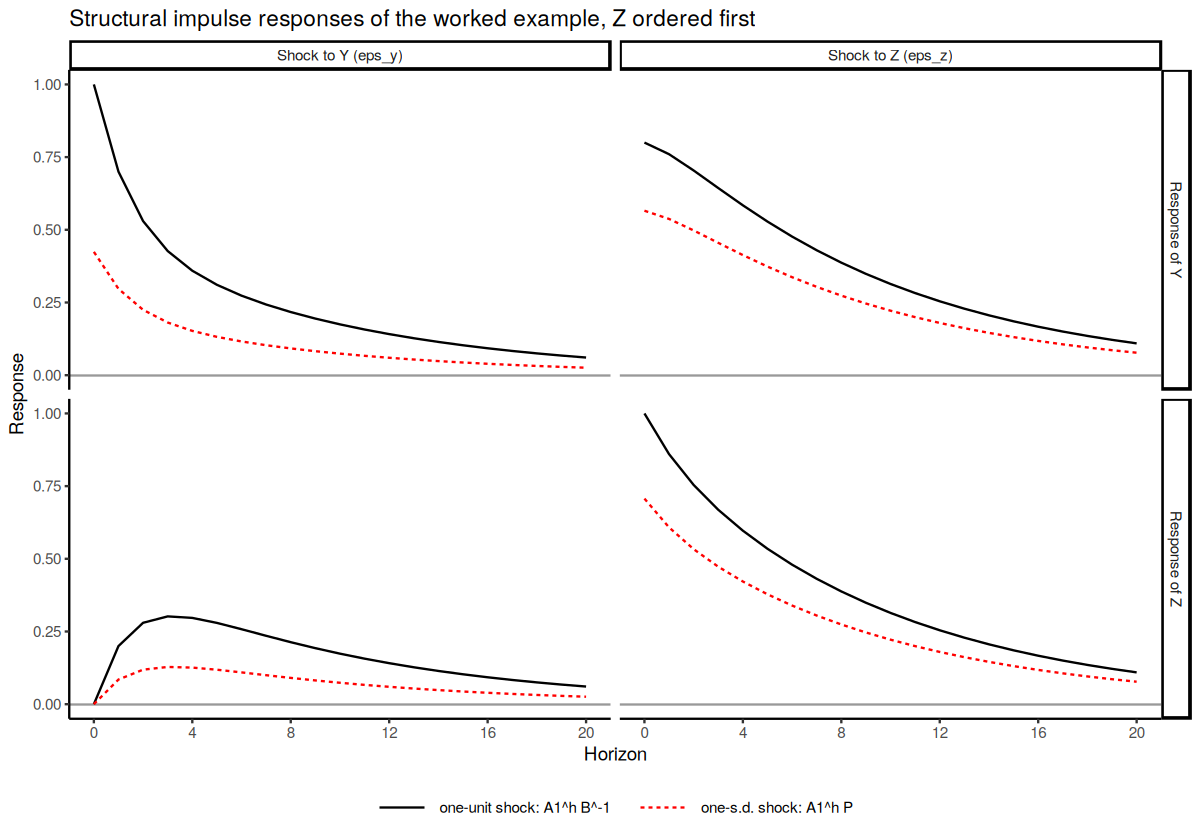

In [4]:
# Step 6: structural impulse responses, Psi_h = A1^h B^-1 (one-unit shocks) and A1^h P (one s.d.)
H <- 20
Phi      <- vma(list(A1), h = H)
Psi_unit <- array(apply(Phi, 3, function(F) F %*% Binv), dim(Phi))
Psi_sd   <- array(apply(Phi, 3, function(F) F %*% P),    dim(Phi))
irf_tab <- data.frame(h = 0:H,
                      `Y to eps_y` = Psi_unit[1, 1, ], `Z to eps_y` = Psi_unit[2, 1, ],
                      `Y to eps_z` = Psi_unit[1, 2, ], `Z to eps_z` = Psi_unit[2, 2, ],
                      check.names = FALSE)
cat("Responses to one-unit structural shocks:\n")
print(round(irf_tab[c(1:5, 9, 13, 21), ], 3), row.names = FALSE)
cat("\nOne-s.d. responses = one-unit responses times (sigma_y, sigma_z) = (",
    paste(round(sd_eps, 4), collapse = ", "), ")\n")
LR_cum <- solve(diag(2) - A1) %*% Binv; rownames(LR_cum) <- c("Y", "Z")
cat("Long-run cumulated one-unit responses, (I - A1)^-1 B^-1:\n"); print(round(LR_cum, 3))

options(repr.plot.height = 7)
irf_grid(list(`one-unit shock: A1^h B^-1` = Psi_unit, `one-s.d. shock: A1^h P` = Psi_sd),
         shocks = c("Shock to Y (eps_y)", "Shock to Z (eps_z)"),
         title = "Structural impulse responses of the worked example, Z ordered first")

**Reading the output.** The table reproduces the hand calculations: $(1,\,0,\,0.8,\,1)$ on impact, $(0.7,\,0.2,\,0.76,\,0.86)$ at $h=1$ and $(0.53,\,0.28,\,0.704,\,0.754)$ at $h=2$. After a few periods the responses to each shock become almost identical for $Y$ and $Z$ (both $0.141$ to $\varepsilon_y$ and both $0.254$ to $\varepsilon_z$ at $h=12$) and decline by the factor $0.9$ per period: the eigenvector of the eigenvalue $0.9$ is $(1,1)'$, so the slow component moves $Y$ and $Z$ together, while the fast component (eigenvalue $0.5$, eigenvector $(1,-1)'$) dies out within a few periods.

A one-unit $\varepsilon_z$ shock has the larger and more persistent effect on $Y$ (0.8 on impact and 0.254 at $h=12$, against 1.0 and 0.141 for $\varepsilon_y$), because it moves $Z$ as well and $Z$ feeds back into $Y$. Scaling to one standard deviation reinforces this: $\varepsilon_z$ is the larger shock ($\sigma_z=0.707$ against $\sigma_y=0.424$), so the dashed red lines for $\varepsilon_y$ shrink to 42% of the one-unit responses while those for $\varepsilon_z$ shrink only to 71%. The long-run cumulated responses, $(I-A_1)^{-1}B^{-1}=\begin{bmatrix}6&8.8\\4&9.2\end{bmatrix}$, are large because the dominant eigenvalue is close to one.

## Step 7: the variance decomposition

At $n=1$ the forecast error is $\Psi_0\varepsilon_{t+1}$. With one-standard-deviation responses $P$, the one-step forecast-error variance of $Y$ is $0.4243^2+0.5657^2=0.18+0.32=0.5=\sigma_1^2$, of which $\varepsilon_y$ contributes $0.18/0.5=36\%$ and $\varepsilon_z$ contributes $0.32/0.5=64\%$. For $Z$ the one-step variance is $0.7071^2=0.5$, all of it from $\varepsilon_z$: the recursive restriction rules out any contemporaneous effect of $\varepsilon_y$ on $Z$.

### Predict

As the horizon grows, will the share of $\varepsilon_z$ in the forecast-error variance of $Y$ rise or fall? Will $\varepsilon_y$ ever account for much of the variance of $Z$?

In [5]:
# Step 7: forecast-error variance decomposition, Z ordered first (percentages)
fv_zy <- fevd_table(Psi_sd, horizons = c(1, 2, 4, 8, 12, 20))
print(fv_zy, row.names = FALSE)

 variable n-step    FEV % eps_y % eps_z
        Y      1 0.5000    36.0    64.0
        Y      2 0.8770    30.6    69.4
        Y      4 1.4153    24.8    75.2
        Y      8 1.9962    20.9    79.1
        Y     12 2.2462    19.7    80.3
        Y     20 2.4001    19.0    81.0
        Z      1 0.5000     0.0   100.0
        Z      2 0.8770     0.8    99.2
        Z      4 1.4153     2.7    97.3
        Z      8 1.9962     4.5    95.5
        Z     12 2.2462     5.1    94.9
        Z     20 2.4001     5.4    94.6


**Reading the output.** At $n=1$ the shares are those computed by hand: $Y$ is 36% $\varepsilon_y$ and 64% $\varepsilon_z$; $Z$ is 100% $\varepsilon_z$. The forecast-error variances are $0.5$ for both variables, the diagonal of $\Sigma_e$, and they grow with the horizon (2.40 at $n=20$) towards the unconditional variances. As the horizon lengthens, the share of $\varepsilon_z$ in the forecast-error variance of $Y$ **rises**, to 75% at $n=4$ and 81% at $n=20$, because $\varepsilon_z$ moves $Y$ both directly and through the persistent feedback from $Z$. $\varepsilon_y$ never explains more than about 5% of the variance of $Z$: under this identification $Z$ is close to exogenous with respect to $Y$, and $Y$ is largely driven by $Z$ shocks.

Cholesky factor with Y first:


   eps_y  eps_z
Y 0.7071 0.0000
Z 0.5657 0.4243


sigma_y^2 = 0.5    sigma_z^2 = 0.18    b21 = -0.8 



Share of the Z shock in each forecast-error variance, under the two orderings:


 variable n-step % eps_z, Z first % eps_z, Y first
        Y      1             64.0              0.0
        Y      4             75.2              2.7
        Y     12             80.3              5.1
        Y     20             81.0              5.4
        Z      1            100.0             36.0
        Z      4             97.3             24.8
        Z     12             94.9             19.7
        Z     20             94.6             19.0


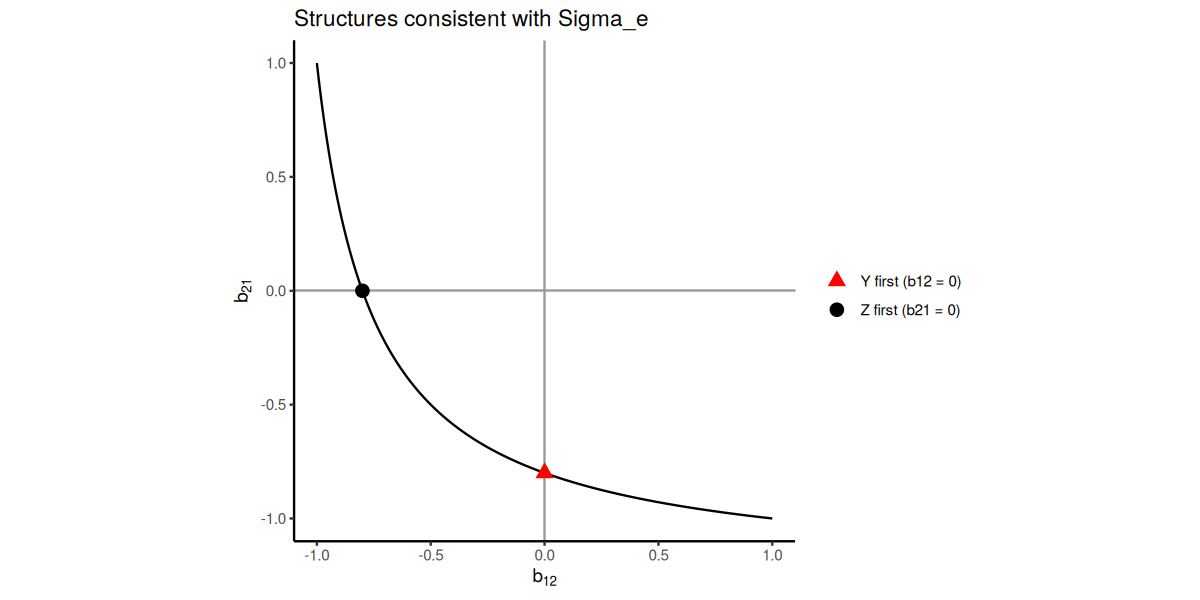

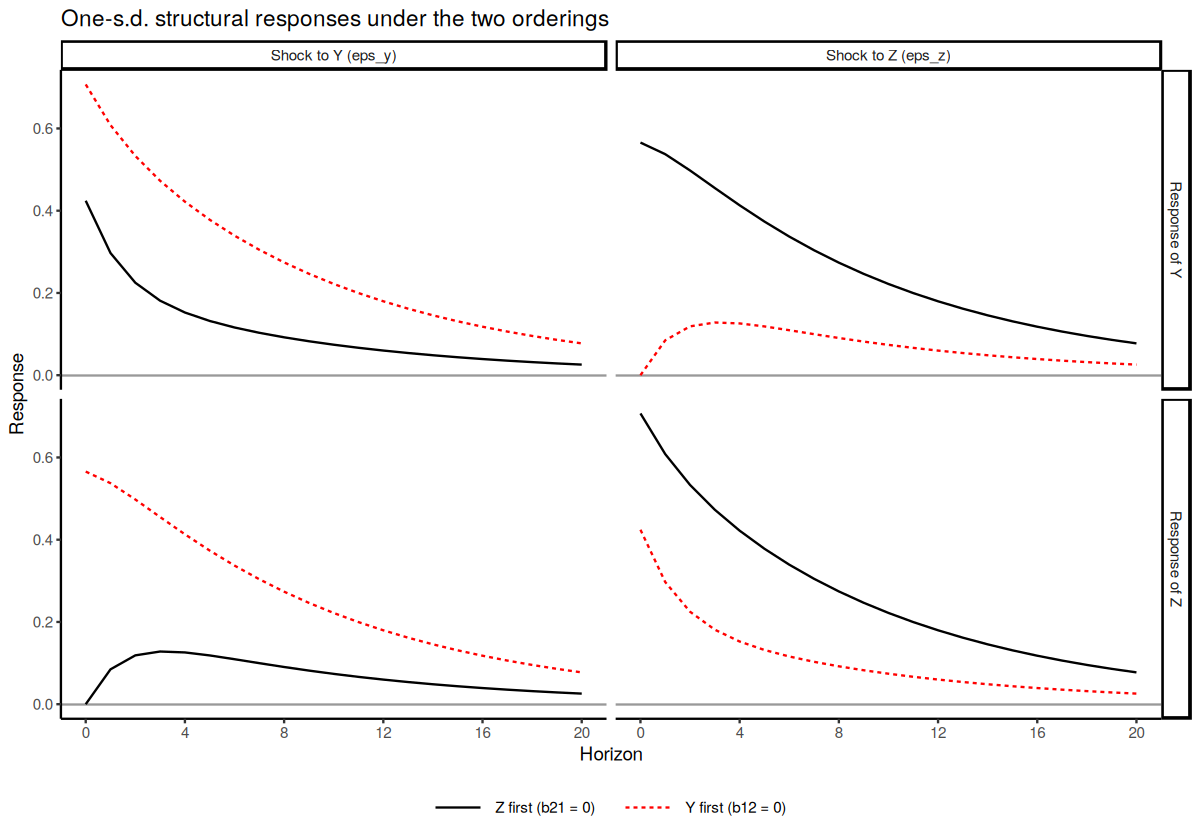

In [6]:
# Step 8: reverse the ordering (Y first, b12 = 0) and compare
P_yz <- t(chol(Sigma_e)); dimnames(P_yz) <- list(c("Y", "Z"), c("eps_y", "eps_z"))
Binv_yz <- sweep(P_yz, 2, diag(P_yz), "/")
cat("Cholesky factor with Y first:\n"); print(round(P_yz, 4))
cat("sigma_y^2 =", round(P_yz[1, 1]^2, 4), "   sigma_z^2 =", round(P_yz[2, 2]^2, 4),
    "   b21 =", round(solve(Binv_yz)[2, 1], 4), "\n\n")

Psi_sd_yz <- array(apply(Phi, 3, function(F) F %*% P_yz), dim(Phi))
h_show <- c(1, 4, 12, 20)
cmp <- cbind(fevd_table(Psi_sd, h_show)[, c(1, 2, 5)],
             fevd_table(Psi_sd_yz, h_show)[, 5])
names(cmp) <- c("variable", "n-step", "% eps_z, Z first", "% eps_z, Y first")
cat("Share of the Z shock in each forecast-error variance, under the two orderings:\n")
print(cmp, row.names = FALSE)

# Every (b12, b21) on this curve reproduces Sigma_e; each ordering picks one point
s1 <- Sigma_e[1, 1]; s2 <- Sigma_e[2, 2]; s12 <- Sigma_e[1, 2]
b21_of <- function(b12) -(s12 + b12 * s2) / (s1 + b12 * s12)
curve <- data.frame(b12 = seq(-1, 1, by = 0.01)); curve$b21 <- b21_of(curve$b12)
pts <- data.frame(b12 = c(-s12 / s2, 0), b21 = c(0, b21_of(0)),
                  ordering = c("Z first (b21 = 0)", "Y first (b12 = 0)"))
options(repr.plot.height = 5)
print(ggplot(curve, aes(b12, b21)) + theme_classic() +
  geom_hline(yintercept = 0, colour = "grey60") + geom_vline(xintercept = 0, colour = "grey60") +
  geom_line() +
  geom_point(data = pts, aes(colour = ordering, shape = ordering), size = 3.5) +
  scale_colour_manual(values = c("red", "black"), name = NULL) +
  scale_shape_manual(values = c(17, 16), name = NULL) + coord_equal() +
  labs(x = expression(b[12]), y = expression(b[21]),
       title = "Structures consistent with Sigma_e"))
options(repr.plot.height = 7)
irf_grid(list(`Z first (b21 = 0)` = Psi_sd, `Y first (b12 = 0)` = Psi_sd_yz),
         shocks = c("Shock to Y (eps_y)", "Shock to Z (eps_z)"),
         title = "One-s.d. structural responses under the two orderings")

**Reading the output.** With $Y$ first, the Cholesky factor is $\begin{bmatrix}0.7071&0\\0.5657&0.4243\end{bmatrix}$, so $\sigma_y^2=0.5$, $\sigma_z^2=0.18$ and $b_{21}=-0.8$. The conclusions reverse:

- **Variance decomposition.** With $Z$ first, $\varepsilon_z$ explains 64% of the one-step forecast-error variance of $Y$ and 81% at $n=20$; with $Y$ first it explains 0% and 5%. For $Z$ the share of its own shock falls from 100% to 36% at $n=1$.
- **Impulse responses.** Under one ordering $\varepsilon_z$ moves both variables on impact; under the other $\varepsilon_y$ does. Because $A_1$ and $\Sigma_e$ are symmetric in $Y$ and $Z$, the two sets of responses are mirror images of each other, with the roles of $Y$ and $Z$ exchanged. Which variable "drives" the other is decided entirely by the restriction.
- **The identification curve.** Every point on the curve $b_{21}=-(\sigma_{12}+b_{12}\sigma_2^2)/(\sigma_1^2+b_{12}\sigma_{12})$ reproduces $\Sigma_e$. The two orderings are its intercepts, $(b_{12},b_{21})=(-0.8,\,0)$ and $(0,\,-0.8)$. Any other point — for example $(-0.5,\,-0.5)$, with both variables responding to each other — is equally consistent with the data.

With a residual correlation of $0.8$ the ordering decides the answer. This is the general lesson: check the residual correlations before interpreting orthogonalized results, justify the ordering on economic grounds, and when the correlations are large, report how the conclusions change with the ordering.

## The steps in summary

| Step | Computation | Result in the example |
|---|---|---|
| 1. Reduced form | OLS: $\hat A_1$, $\hat\Sigma_e$; check stability and the residual correlation | eigenvalues 0.9, 0.5; $\rho_{12}=0.8$ |
| 2. Ordering | economic argument: which variable does not respond within the period? | $Z$ first ($b_{21}=0$) |
| 3. Cholesky factor | `t(chol())` of $\hat\Sigma_e$ in the chosen order, then reorder | $P=\begin{bmatrix}0.4243&0.5657\\0&0.7071\end{bmatrix}$ |
| 4. Structure | $\sigma$'s from $\operatorname{diag}(P)$; $B^{-1}$ = columns of $P$ divided by their diagonal | $\sigma_y^2=0.18$, $\sigma_z^2=0.5$, $b_{12}=-0.8$ |
| 5. Coefficients and shocks | $\Gamma_i=BA_i$; $\varepsilon_t=Be_t$ | $c_{11}=0.54$, $c_{12}=-0.36$; $e_{1t}=\varepsilon_{yt}+0.8\varepsilon_{zt}$ |
| 6. Impulse responses | $\Psi_h=\Phi_hB^{-1}$ (one unit) or $\Phi_hP$ (one s.d.) | impact $(1,0)$ and $(0.8,1)$ |
| 7. Variance decomposition | sums of squared one-s.d. responses | $Y$: 64% $\varepsilon_z$ at $n=1$ |
| 8. Robustness | repeat with other plausible orderings | conclusions reverse |

# 10&nbsp;&nbsp;Specification, estimation and diagnostics

## Determining the lag length

Let the unrestricted VAR have $p_u$ lags and the restricted VAR $p_r<p_u$ lags, both estimated **on the same sample** of $T$ usable observations, with residual covariance matrices $\hat\Sigma_u$ and $\hat\Sigma_r$.

**Likelihood ratio test.** Following Sims (1980) and Enders (2015, Ch. 5),

$$
LR=(T-c)\big(\ln|\hat\Sigma_r|-\ln|\hat\Sigma_u|\big)\;\overset{a}{\sim}\;\chi^2(q),
$$

where $q=k^2(p_u-p_r)$ is the number of restrictions ($k^2$ coefficients per lag) and $c$ is the number of parameters estimated in **each equation** of the unrestricted system, $c=1+kp_u$ with an intercept. The factor $T-c$ instead of $T$ is a small-sample correction that makes the test less likely to reject. Reject the shorter lag length if $LR$ exceeds the $\chi^2(q)$ critical value.

**Information criteria.** The multivariate versions are

$$
AIC=T\ln|\hat\Sigma|+2N,\qquad SBC\ (=BIC)=T\ln|\hat\Sigma|+N\ln T,
$$

where $N$ is the total number of parameters in all equations, $N=k^2p+k$ with intercepts (plus any other deterministic terms). Equivalently, $AIC^\ast=-2\ln L+2N$ and $BIC^\ast=-2\ln L+N\ln T$. Choose the lag length that **minimizes** the criterion, comparing all candidates on a common sample. As in the univariate case, SBC tends to choose shorter lags than AIC. Adding lags will not fix an omitted-variable problem.

## Estimation

- The reduced-form VAR is estimated equation by equation by OLS: the right-hand side is predetermined, and under correct specification the residuals are serially uncorrelated.
- **Variable selection** should be guided by economic theory and data availability. A relevant variable left out of the system ends up in the residuals, which can then be correlated with the regressors and with each other.
- With $k$ variables and $p$ lags the VAR $X_t=A_0+A_1X_{t-1}+\cdots+A_pX_{t-p}+e_t$ has $k+pk^2$ parameters, plus any deterministic seasonal or trend terms. VARs are heavily **over-parameterized**: many individual coefficients will be insignificant, and they are not meant to be interpreted one by one. Their joint implications — impulse responses and variance decompositions — are the objects of interest.

## Diagnostics and forecasting

- **Residual checks.** Test the residuals for serial correlation with the multivariate portmanteau (Ljung–Box) or Lagrange-multiplier tests, the system counterparts of the Ljung–Box test of Lecture 9; examine normality and heteroskedasticity as appropriate. If the diagnostics fail, revisit the variables, the lag length and the deterministic terms.
- **Stability.** Check that all companion eigenvalues lie inside the unit circle (Section 4).
- **Forecasting.** Iterate the estimated VAR forward using conditional expectations, $E_tX_{t+n}=\hat A_0+\hat A_1E_tX_{t+n-1}+\cdots$; forecast-error variances follow from the VMA (Section 5), and prediction intervals can also be obtained by simulation.

## Exercises

### Exercise 1 — From structure to reduced form
Let $b_{12}=0.5$, $b_{21}=0$, $\sigma_y^2=\sigma_z^2=1$ and $\Gamma_1=\begin{bmatrix}0.6&0.2\\0.1&0.5\end{bmatrix}$. (a) Compute $B^{-1}$, $A_1=B^{-1}\Gamma_1$ and $\Sigma_e$. (b) Which variable responds within the period to which shock? (c) Compute $\Psi_0$ and $\Psi_1$. (d) Show that the Cholesky factorization with $Z$ ordered first recovers $B$ exactly, while ordering $Y$ first does not. Check your answers with `solve()`, `chol()` and `vma()`.

### Exercise 2 — Stability
Let $A_1=\begin{bmatrix}0.8&a\\0.2&0.6\end{bmatrix}$. (a) Write $\det(I-A_1z)$ as a function of $a$. (b) For which value of $a$ does the VAR have a unit root? (c) For which values of $a$ is it stable? (Hint: the eigenvalues are real for some values of $a$ and complex for others.) (d) Check your answers with `eigen()` for a grid of values of $a$.

### Exercise 3 — Cholesky identification and variance decomposition by hand
A bivariate VAR(1) has $\hat A_1=\begin{bmatrix}0.5&0.1\\0.2&0.6\end{bmatrix}$ and $\hat\Sigma_e=\begin{bmatrix}1.0&0.5\\0.5&2.0\end{bmatrix}$. (a) Compute the Cholesky factor for the ordering $(Y,Z)$ and for $(Z,Y)$, and the implied $b_{12}$, $b_{21}$, $\sigma_y^2$ and $\sigma_z^2$. (b) Compute the one-unit structural responses $\Psi_0$ and $\Psi_1$ under each ordering. (c) Compute the one- and two-step variance decompositions of both variables under each ordering. (d) Suppose $Y$ is a policy interest rate set by a central bank that observes $Z$, a monthly activity indicator, only with a one-month lag. Which ordering would you use for monthly data, and why?

### Exercise 4 — Lag length
A three-variable VAR with intercepts is estimated on $T=200$ usable observations. With 4 lags, $\ln|\hat\Sigma_u|=-15.40$; with 2 lags on the same sample, $\ln|\hat\Sigma_r|=-15.20$. (a) Compute the LR statistic of Section 10, its degrees of freedom and the 5% critical value. (b) Compute AIC and SBC for both lag lengths. (c) Which lag length does each criterion choose, and why might they disagree?



## Suggested reading

- Enders, W. (2015), *Applied Econometric Time Series*, 4th ed., Wiley: Ch. 5 (the primitive and standard-form VAR, stability, identification, impulse responses, variance decomposition, lag length — the basis of this lecture).
- Hamilton, J. D. (1994), *Time Series Analysis*, Princeton University Press: Chs. 10–11 (covariance-stationary vector processes; estimation, impulse responses and variance decompositions of VARs).
- Lütkepohl, H. (2005), *New Introduction to Multiple Time Series Analysis*, Springer: Chs. 2–4 (stable VAR processes, estimation, lag-order selection and diagnostics) and Ch. 9 (structural VARs).
- Kilian, L. and Lütkepohl, H. (2017), *Structural Vector Autoregressive Analysis*, Cambridge University Press — the modern reference on identification.
- Pfaff, B. (2008), *Analysis of Integrated and Cointegrated Time Series with R*, 2nd ed., Springer: Ch. 2 — the companion to **vars**.
- Stock, J. H. and Watson, M. W. (2001), "Vector autoregressions", *Journal of Economic Perspectives* 15(4), 101–115 — a short, readable introduction.

**Original papers.**

*Foundations:* Wold (1938, *A Study in the Analysis of Stationary Time Series*); Zellner (1962, *JASA*); Sims (1980, *Econometrica*); Sims (1986, *Federal Reserve Bank of Minneapolis Quarterly Review*); Bernanke (1986, *Carnegie-Rochester Conference Series on Public Policy*).

*Identification:* Blanchard and Quah (1989, *AER*); Christiano, Eichenbaum and Evans (1999, *Handbook of Macroeconomics* 1A); Uhlig (2005, *JME*); Rubio-Ramírez, Waggoner and Zha (2010, *REStud*); Stock and Watson (2018, *Economic Journal*).

*Inference on impulse responses:* Kilian (1998, *REStat*).

*Software:* Pfaff (2008), "VAR, SVAR and SVEC models: implementation within R package vars", *Journal of Statistical Software* 27(4).

*Surveys:* Ramey (2016, *Handbook of Macroeconomics* 2A) on macroeconomic shocks and their propagation.

## Appendix A: R quick reference

| Task | Function | Notes |
|---|---|---|
| Cholesky factor | `t(chol(S))` | `chol()` returns the **upper** factor $U$ with $S=U'U$; reorder rows and columns of `S` to change the ordering |
| Eigenvalues and roots | `eigen(A)`, `polyroot()` | roots of $\det(I-A_1z)$ are the reciprocals of the eigenvalues |
| VMA matrices from known $A_i$ | `vma(A, h)` | this lecture's helper: $\Phi_0,\dots,\Phi_h$ |
| Variance decomposition from responses | `fevd_table(Psi_sd, horizons)` | this lecture's helper; `Psi_sd` holds one-s.d. responses |
| Lag-length selection | `vars::VARselect(y, lag.max, type)` | AIC, HQ, SC (BIC) and FPE |
| Estimate a VAR($p$) | `vars::VAR(y, p, type = "const")` | OLS equation by equation; the column order of `y` is the Cholesky ordering |
| Coefficients | `vars::Acoef(fit)`, `vars::Bcoef(fit)`, `coef(fit)` | $\hat A_i$; all coefficients; estimates with standard errors |
| Residual covariance and correlation | `summary(fit)`, elements `covres` and `corres` | $\hat\Sigma_e$ (degrees-of-freedom corrected) |
| Stability | `vars::roots(fit)` | moduli of the companion eigenvalues; all must be below one |
| Serial correlation | `vars::serial.test(fit, lags.pt, type = "PT.adjusted")` | also `type = "BG"` for the LM test |
| Normality, ARCH | `vars::normality.test(fit)`, `vars::arch.test(fit)` | |
| VMA matrices from a fitted VAR | `vars::Phi(fit, nstep)`, `vars::Psi(fit, nstep)` | $\hat\Phi_j$; $\hat\Phi_j\hat P$ (Cholesky) |
| Impulse responses | `vars::irf(fit, impulse, response, n.ahead, ortho, cumulative, boot, runs, ci)` | `ortho = TRUE`: one-s.d. Cholesky shocks |
| Variance decomposition | `vars::fevd(fit, n.ahead)` | uses the Cholesky ordering |
| Forecasting | `predict(fit, n.ahead, ci)` | point forecasts and intervals |
| Granger causality | `vars::causality(fit, cause)` | Wald test; also instantaneous causality |
| Short-run and long-run SVARs | `vars::SVAR(fit, Amat, Bmat)`, `vars::BQ(fit)` | `NA` marks a free coefficient; Blanchard–Quah |
